In [1]:
import sys
sys.path.append('/glade/u/home/manishrv/documents/croc/dev/CrocoLens')
%load_ext autoreload
%autoreload 2
from CrocoLens.regional_domain import RegionalDomain
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy
import calendar
import xarray as xr
import json

In [2]:
glorys_monthly_means = xr.open_dataset("/glade/derecho/scratch/manishrv/glorys_data/nwa_2000_monthly_means/glorys_monthly_means_regridded_to_nwa.nc")
cesm_monthly_means = xr.open_mfdataset("/glade/derecho/scratch/manishrv/archive/gustavo-glorys-2/ocn/hist/gustavo-glorys-2.mom6.h.native.2000*.nc")
hgrid = xr.open_dataset("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_hgrid.nc")

<GeoAxes: >

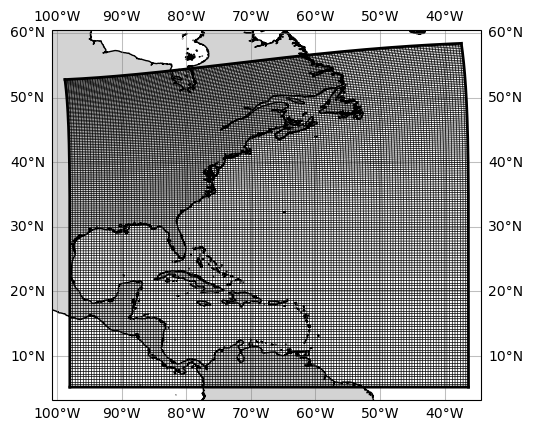

In [3]:
#Plot Raw
rd = RegionalDomain("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_hgrid.nc")
rd.plot_map()

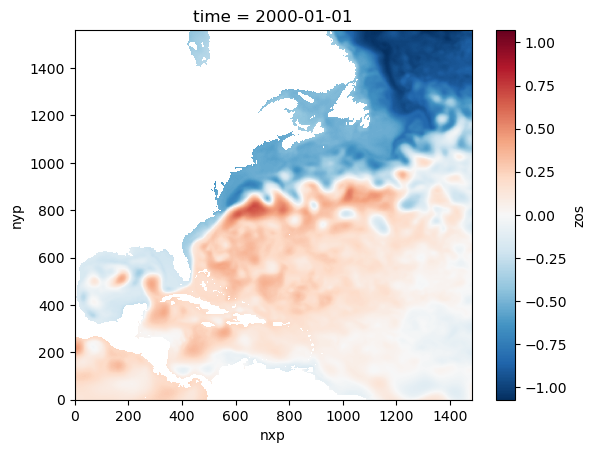

In [4]:
glorys_monthly_means.zos[0].plot()

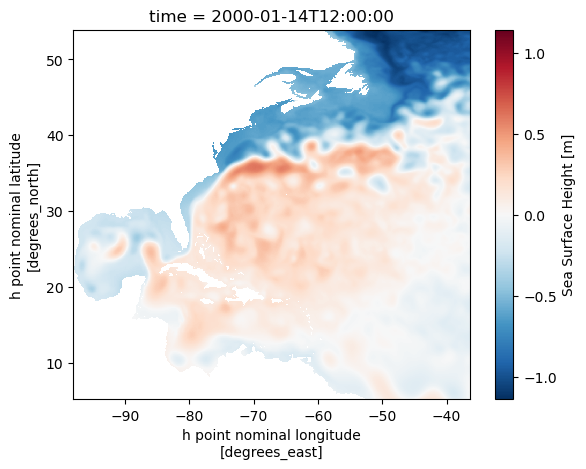

In [5]:
cesm_monthly_means.SSH[0].plot()

In [6]:
# Set Vars
months = calendar.month_abbr[1:]



t_points = rd.get_point_type_dataset("t")
extent = [
                hgrid.x.min() - 2,
                hgrid.x.max() + 2,
                hgrid.y.min() - 2,
                hgrid.y.max() + 2,
            ]

var_config = {
    "ssh":{
        "glorys_var": "zos",
        "cesm_var": "SSH",
        "output_var": "ssh",
        "vmin" : -1.2,
        "vmax" : 1.2,
        "diff_vmin" : -1,
        "diff_vmax" : 1 ,
    },
    "mlotst":{
        "glorys_var": "mlotst",
        "cesm_var": "mlotst",
        "output_var": "mlotst",
        "vmin" : 0,
        "vmax" : 300,
        "diff_vmin" : -100,
        "diff_vmax" : 100,
    }
}
with open("/glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/monthly_stats.json") as f:
    monthly_stats = json.load(f)
# diffs = xr.Dataset()
diffs = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/cesm_glorys_diffs.nc")

In [7]:

# output_var = "ssh"
# diffs[output_var] = xr.zeros_like(cesm_monthly_means[var_config[output_var]["cesm_var"]])
# for i, month in enumerate(months):
#     # Get the data slice for the month
#     cesm_month = cesm_monthly_means[var_config[output_var]["cesm_var"]][i]
#     glorys_month = glorys_monthly_means[var_config[output_var]["glorys_var"]][i,t_points.t_points_y.values, t_points.t_points_x.values]
#     # Rename glorys_month dims to xh, yh
#     renamed_glorys= (glorys_month.rename({"nyp":"yh","nxp":"xh"}))
#     diffs[output_var][i] = renamed_glorys - cesm_month


In [8]:

# monthly_stats[output_var] = {}
# for i, month in enumerate(months):
#     # Get the data slice for the month
#     cesm_month = cesm_monthly_means[var_config[output_var]["cesm_var"]][i]
#     glorys_month = glorys_monthly_means[var_config[output_var]["glorys_var"]][i,t_points.t_points_y.values, t_points.t_points_x.values]
#     # Calculate stats
#     cesm_max = cesm_month.max()
#     cesm_min = cesm_month.min()
#     cesm_avg = cesm_month.weighted(rd.dataset.area).mean()
    
    
#     # Calculate stats for GLORYS
#     glorys_max = glorys_month.max()
#     glorys_min = glorys_month.min()
#     glorys_avg = glorys_month.weighted(rd.dataset.area).mean()
    
#     # Calculate stats for DIFF
#     diff_max = diffs[output_var][i].max()
#     diff_min = diffs[output_var][i].min()
#     diff_avg = diffs[output_var][i].weighted(rd.dataset.area).mean()
    
#     # Store stats in the dictionary
#     monthly_stats[output_var][i] = {
#         "cesm": {"min": cesm_min, "max": cesm_max, "average": cesm_avg},
#         "glorys": {"min": glorys_min, "max": glorys_max, "average": glorys_avg},
#         "diff": {"min": diff_min, "max": diff_max, "average": diff_avg},
#     }

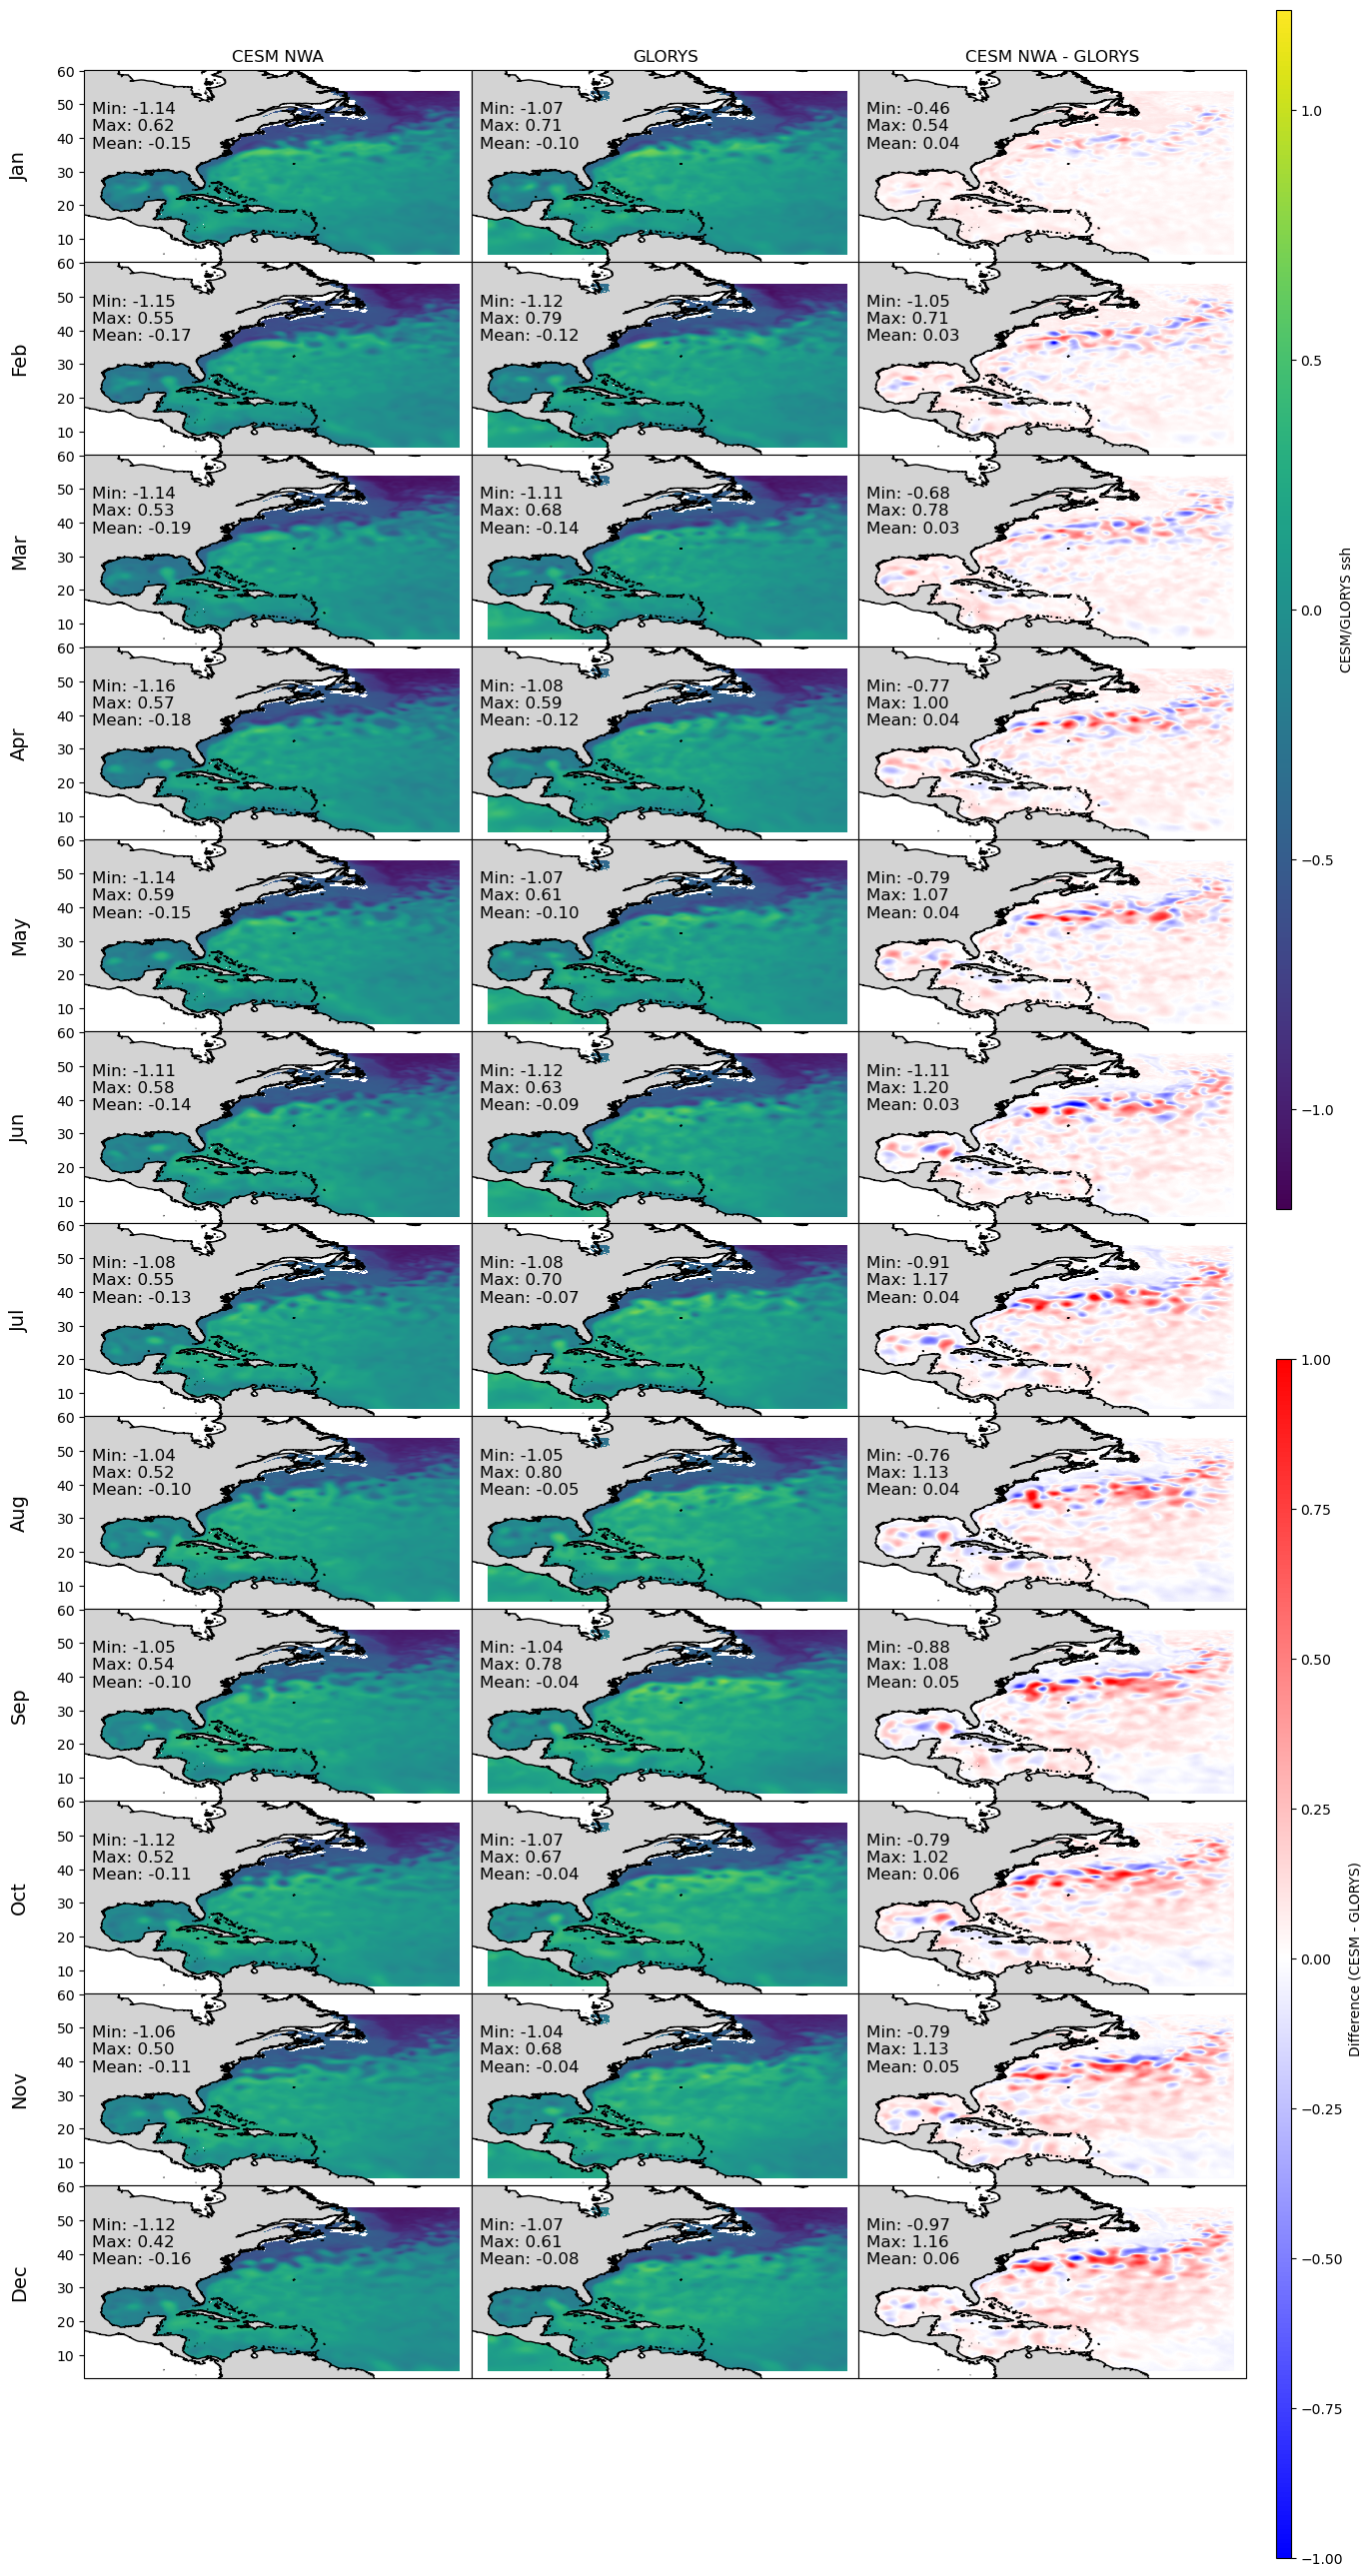

In [14]:
output_var = "ssh"

fig, axes = plt.subplots(12, 3, figsize=(15, 30), subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(hspace=0, wspace=0)



for i, month in enumerate(months):
    # Get the data slice for the month
    cesm_month = cesm_monthly_means[var_config[output_var]["cesm_var"]][i]
    glorys_month = glorys_monthly_means[var_config[output_var]["glorys_var"]][i, t_points.t_points_y.values, t_points.t_points_x.values]
    
    # Update coordinates
    glorys_month = glorys_month.assign_coords({"y": glorys_month.nyp, "x": glorys_month.nxp})
    
    diff_month = diffs[output_var][i]

    for j, (label,data) in enumerate([("cesm",cesm_month), ("glorys",glorys_month), ("diff",diff_month)]):
        stats_text = (
        f"Min: {monthly_stats[output_var][str(i)][label]["min"]:.2f}\n"
        f"Max: {monthly_stats[output_var][str(i)][label]["max"]:.2f}\n"
        f"Mean: {monthly_stats[output_var][str(i)][label]["average"]:.2f}\n"
    )
        ax = axes[i, j]
        
        # Set extent and aspect
        ax.set_extent(extent, ccrs.PlateCarree())
        ax.set_aspect('auto')
        
        # Add land and coastlines
        ax.add_feature(cartopy.feature.LAND, fc="lightgray")
        ax.coastlines(resolution="10m")

        # Plot the data
        if j < 2:
            im = ax.pcolormesh(
                cesm_monthly_means.xh, cesm_monthly_means.yh, data,
                transform=ccrs.PlateCarree(),
                vmin=var_config[output_var]["vmin"], vmax=var_config[output_var]["vmax"]  # Shared colorbar range
            )
        else:
            # Difference plot with its own colorbar
            im_diff = ax.pcolormesh(
                cesm_monthly_means.xh, cesm_monthly_means.yh, data,
                transform=ccrs.PlateCarree(),cmap="bwr",
                vmin=var_config[output_var]["diff_vmin"], vmax=var_config[output_var]["diff_vmax"]
            )
        ax.text(0.02, 0.5, stats_text, transform=ax.transAxes, fontsize=12)

        # Add titles on the first row only
        if i == 0:
            ax.set_title(['CESM NWA', 'GLORYS', 'CESM NWA - GLORYS'][j], fontsize=12)
        if j ==0:
            ax.yaxis.set_visible(True)
            ax.set_ylabel(month, fontsize=14, labelpad=20)

# Add a colorbar
cbar_ax1 = fig.add_axes([0.92, 0.5, 0.01, 0.4])
fig.colorbar(im, cax=cbar_ax1, label="CESM/GLORYS {}".format(output_var))

# Separate colorbar for difference plot
cbar_ax2 = fig.add_axes([0.92, 0.05, 0.01, 0.4])
fig.colorbar(im_diff, cax=cbar_ax2, label="Difference (CESM - GLORYS)")

fig.savefig("plots/glorys_vs_cesm/{}/all_months.png".format(output_var))

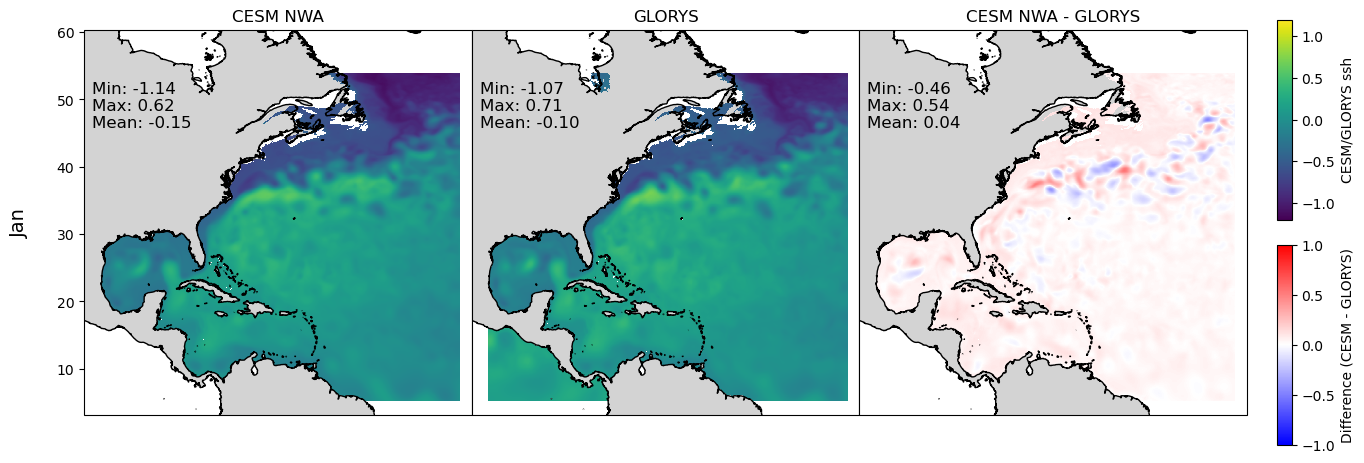

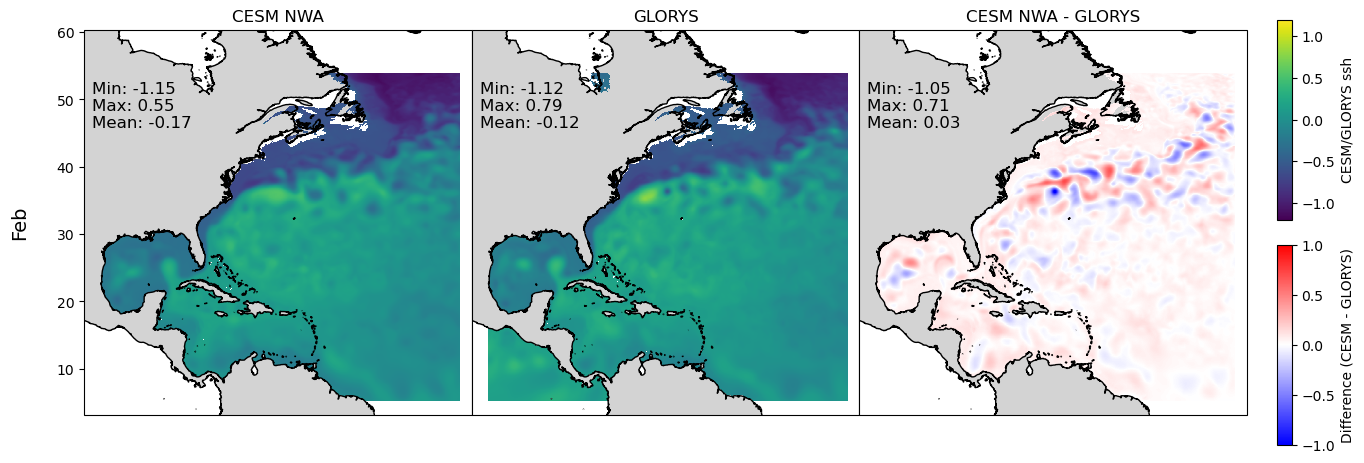

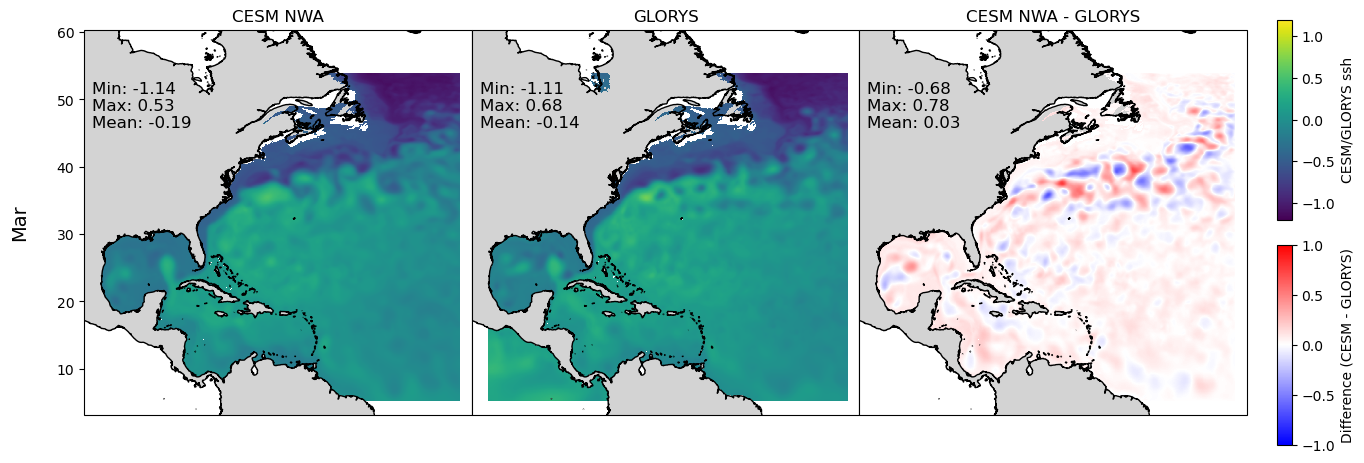

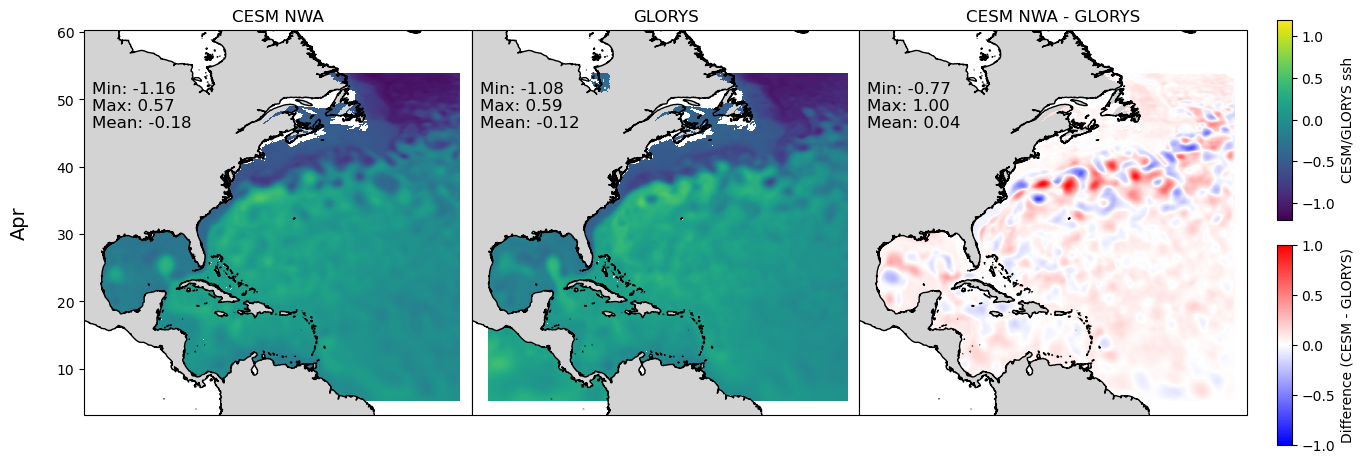

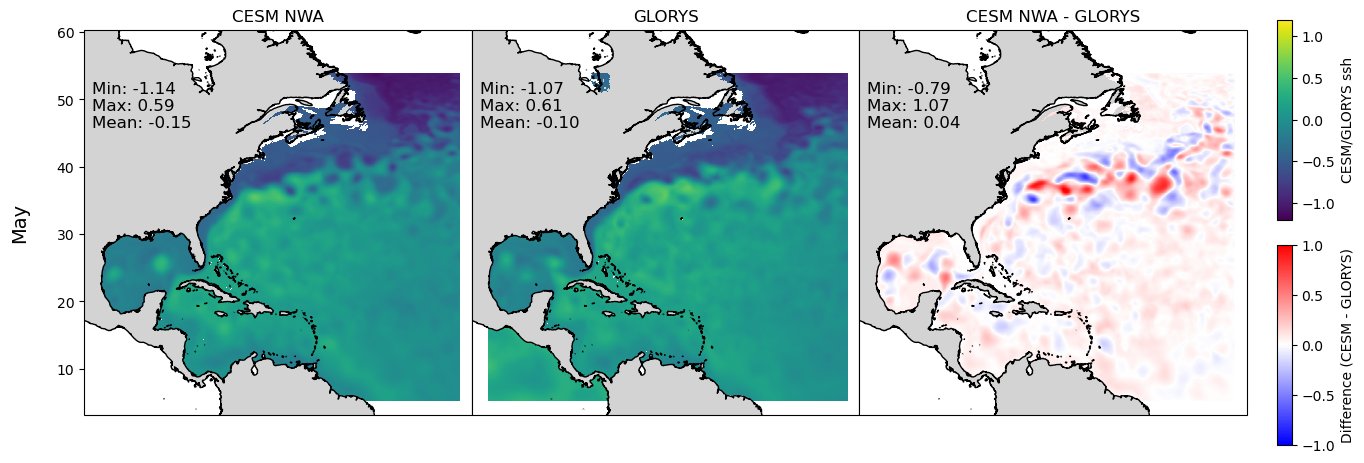

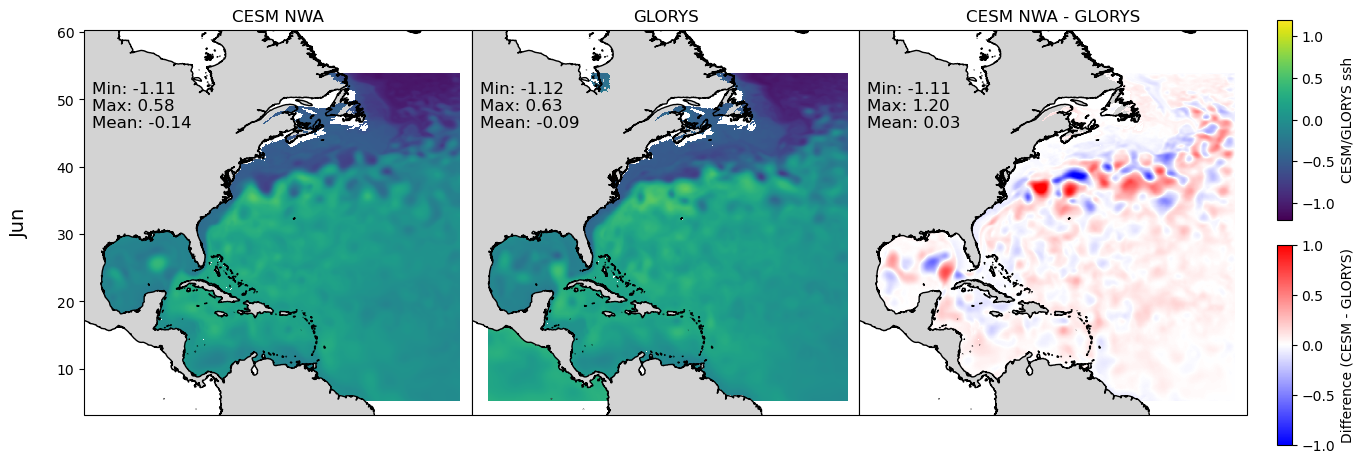

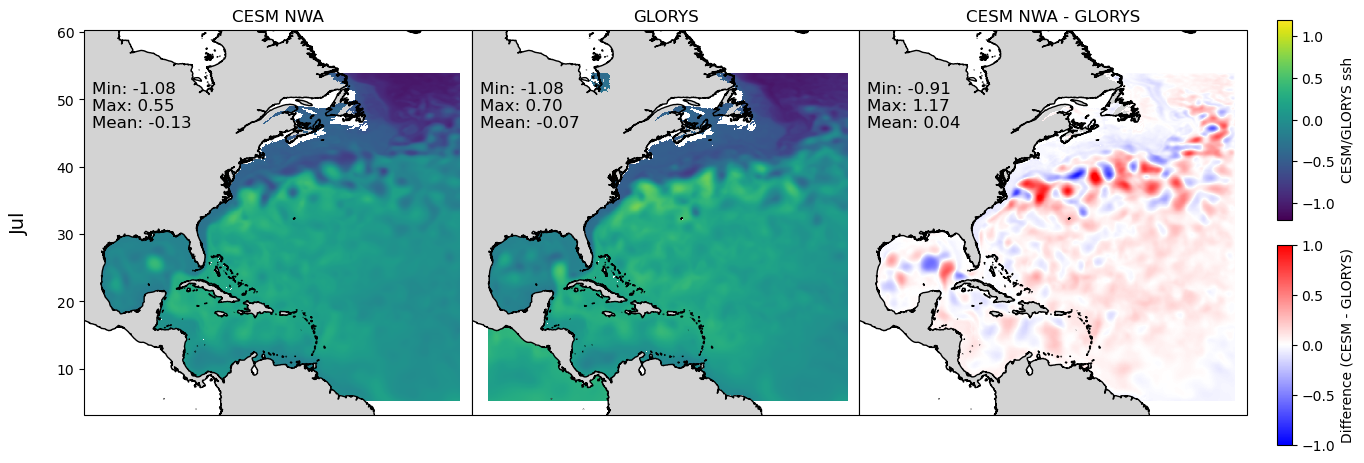

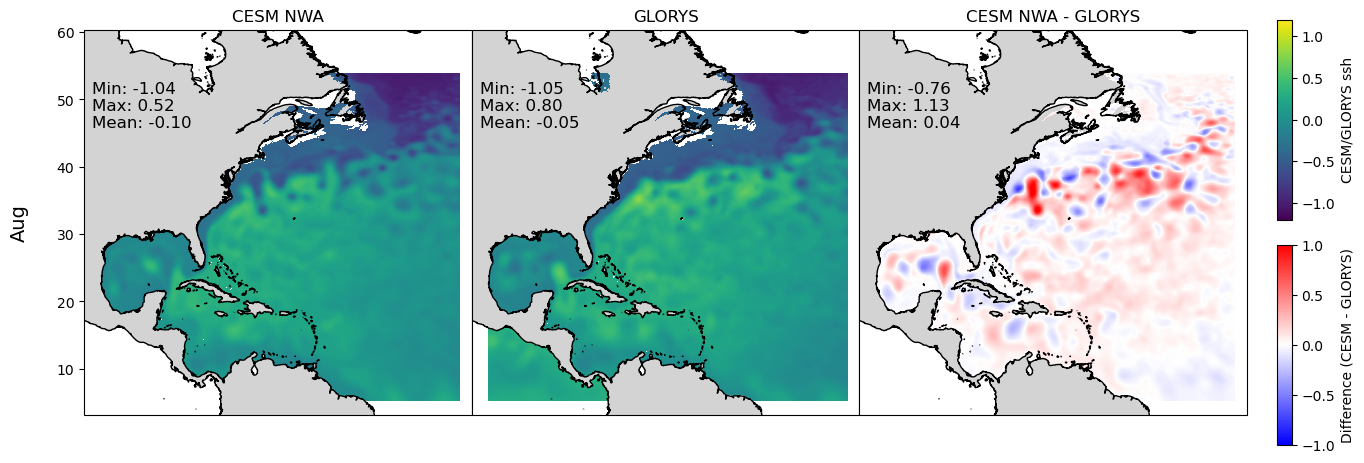

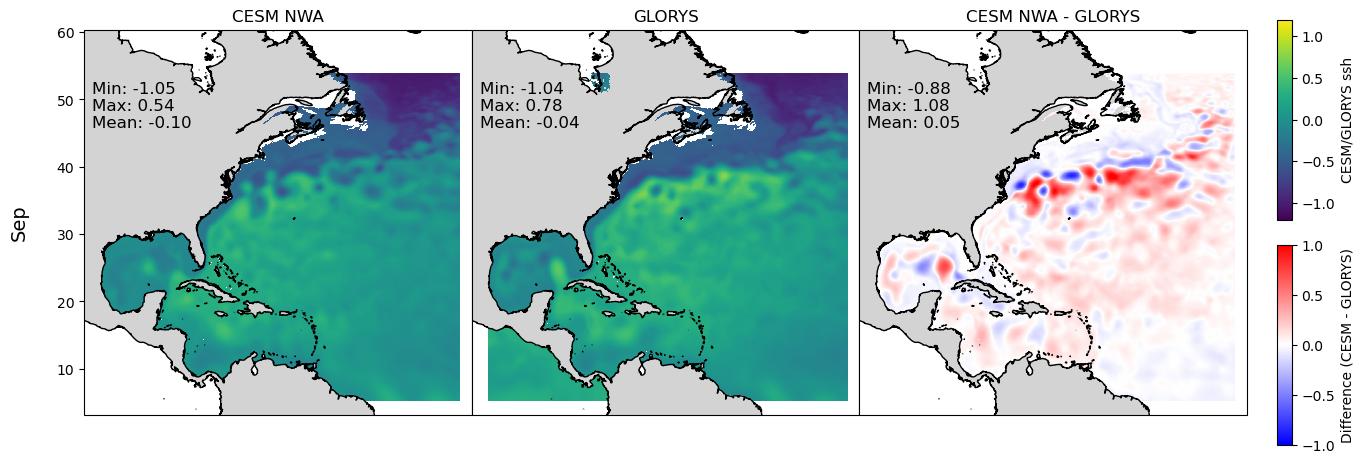

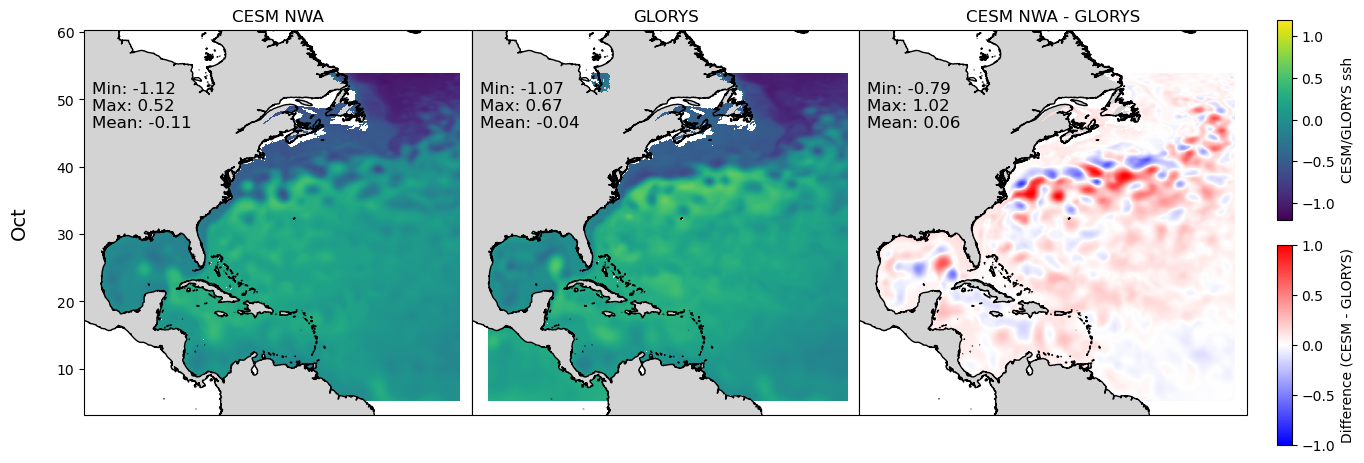

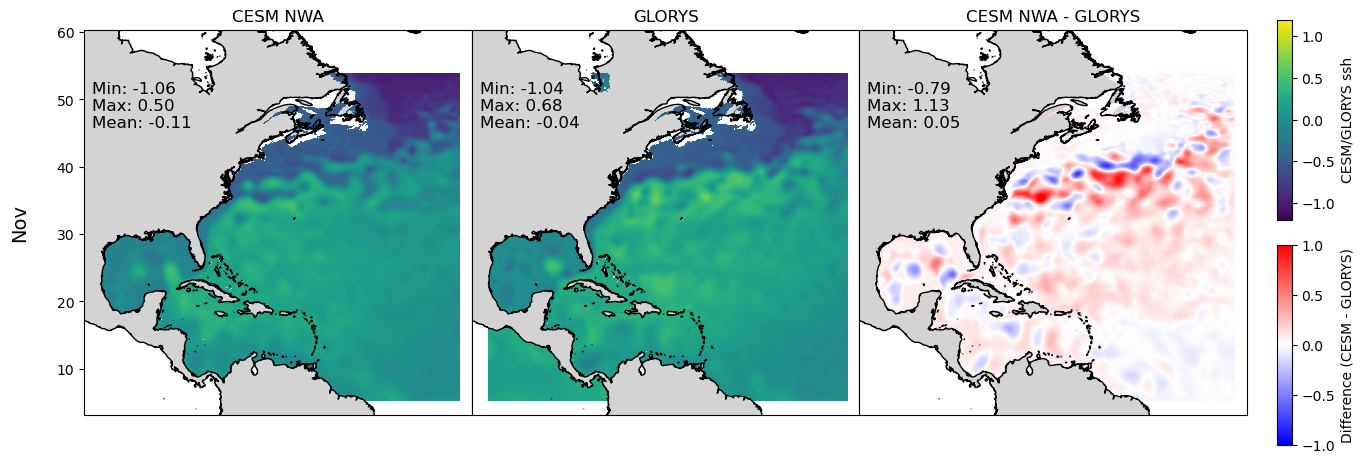

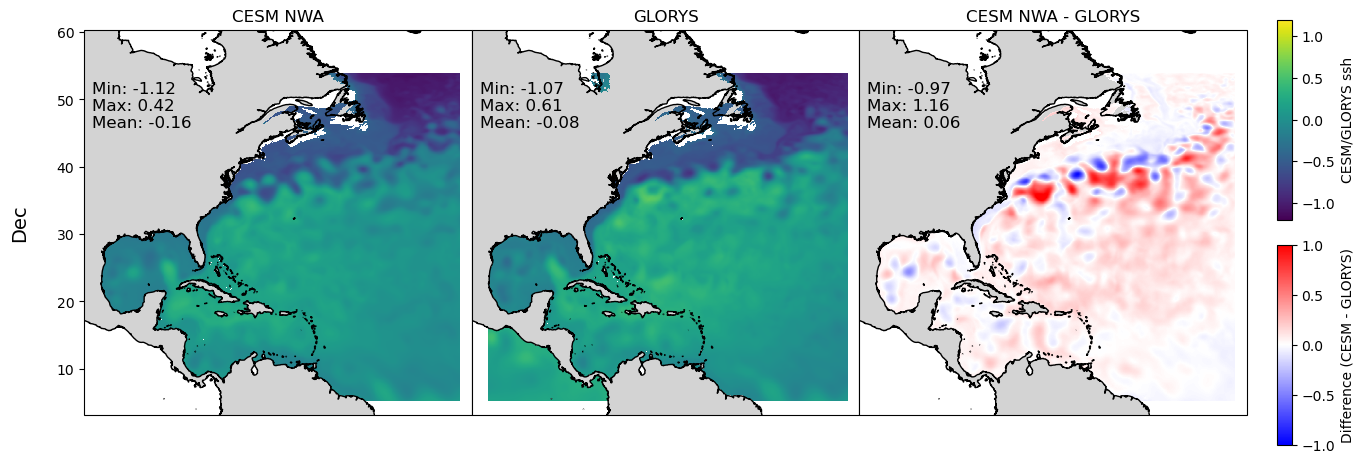

In [13]:
output_var = "ssh"
for i, month in enumerate(months):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.subplots_adjust(hspace=0, wspace=0)
    # Get the data slice for the month
    cesm_month = cesm_monthly_means[var_config[output_var]["cesm_var"]][i]
    glorys_month = glorys_monthly_means[var_config[output_var]["glorys_var"]][i, t_points.t_points_y.values, t_points.t_points_x.values]
    
    # Update coordinates
    glorys_month = glorys_month.assign_coords({"y": glorys_month.nyp, "x": glorys_month.nxp})
    
    diff_month = diffs[output_var][i]

    for j, (label,data) in enumerate([("cesm",cesm_month), ("glorys",glorys_month), ("diff",diff_month)]):
        ax = axes[ j]
        stats_text = (
        f"Min: {monthly_stats[output_var][str(i)][label]["min"]:.2f}\n"
        f"Max: {monthly_stats[output_var][str(i)][label]["max"]:.2f}\n"
        f"Mean: {monthly_stats[output_var][str(i)][label]["average"]:.2f}\n"
    )
        # Set extent and aspect
        ax.set_extent(extent, ccrs.PlateCarree())
        ax.set_aspect('auto')
        
        # Add land and coastlines
        ax.add_feature(cartopy.feature.LAND, fc="lightgray")
        ax.coastlines(resolution="10m")
        

        # Plot the data
        if j < 2:
            im = ax.pcolormesh(
                cesm_monthly_means.xh, cesm_monthly_means.yh, data,
                transform=ccrs.PlateCarree(),
                 vmin=var_config[output_var]["vmin"], vmax=var_config[output_var]["vmax"]
            )
        else:
            # Difference plot with its own colorbar
            im_diff = ax.pcolormesh(
                cesm_monthly_means.xh, cesm_monthly_means.yh, data,
                transform=ccrs.PlateCarree(),   cmap='bwr',
                vmin=var_config[output_var]["diff_vmin"], vmax=var_config[output_var]["diff_vmax"]
            )

        # Add titles on the first row only
        ax.text(0.02, 0.7, stats_text, transform=ax.transAxes, fontsize=12)
        ax.set_title(['CESM NWA', 'GLORYS', 'CESM NWA - GLORYS'][j], fontsize=12)
        if j ==0:
            ax.yaxis.set_visible(True)
            ax.set_ylabel(month, fontsize=14, labelpad=20)

    # Add a colorbar
    cbar_ax1 = fig.add_axes([0.92, 0.5, 0.01, 0.4])
    fig.colorbar(im, cax=cbar_ax1, label="CESM/GLORYS {}".format(output_var))
  
    # Separate colorbar for difference plot
    cbar_ax2 = fig.add_axes([0.92, 0.05, 0.01, 0.4])
    fig.colorbar(im_diff, cax=cbar_ax2, label="Difference (CESM - GLORYS)")
    plt.savefig("plots/glorys_vs_cesm/{}/monthly_plots/{:02d}_monthly_cesm_glorys_comparison_{}".format(output_var,i,month))

